<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/QNN_Watermarking_Zhou2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Watermarking a quantum neural network with grouped and paired training: Zhou and Wu (2025) step by step

**Paper:** Limengnan Zhou and Hanzhou Wu, *Watermarking Quantum Neural Networks Based on Sample Grouped and Paired Training*, arXiv:2506.12675 (2025). https://arxiv.org/abs/2506.12675

**Topic folder:** 26 QML Model Extraction / Theft (intellectual-property protection of quantum models). This notebook reproduces the first paper that proposes **watermarking a quantum neural network (QNN)**.

**What this notebook does.** A QNN is expensive to build (circuit design, trained parameters, data). If somebody steals it, how can the owner prove that it is theirs, using nothing but the predictions of the suspect model? The paper's answer is a *black-box backdoor watermark*: the owner trains the model on clean images plus a few **trigger images** (an MNIST digit with a white 7 x 7 block in a corner, labelled with a *wrong* label). A stolen copy still answers the trigger images with that wrong label, an independently trained model does not. The notebook:

1. downloads MNIST and builds the paper's training sets (100 + 100 images, 10 or 20 of them trigger images) and test sets (100 + 100 clean, 100 trigger);
2. builds the hybrid classical-quantum network of the paper's Fig. 3 (Linear 784 to 16 + ReLU, a 16-qubit circuit with 32 trainable gates, Linear 1 to 1, sigmoid) and simulates the 16-qubit circuit **exactly** inside PyTorch, asserted equal to the real Qiskit circuit;
3. trains non-watermarked and watermarked models with the paper's **sample grouped and paired** order, for the paper's five digit pairs, over several random seeds;
4. re-draws the paper's Tables 1 and 2 next to the numbers measured here, runs the paper's random-order ablation, runs the ownership test of the paper's Eq. (7), and compares with a classical stand-in network and with sklearn classifiers;
5. ends with a verdict per claim ("reproduced" / "not reached" / "exceeded" / "cannot be checked") and a critical reading.

**How to run.** Colab: *Runtime -> Change runtime type -> CPU*, then *Run all*. No GPU and no account are needed (MNIST is public and not gated; a Hugging Face token is only used if the Hugging Face mirror is needed, and then only from Colab Secrets `HF_TOKEN` or the environment variable, never typed into the notebook). `FAST_MODE = True` (default) takes about ten minutes (2 digit pairs, 3 seeds); set `FAST_MODE = False` for the paper's five digit pairs and 5 seeds (roughly 40 to 70 minutes).

**What you get at the end:** Tables 1 and 2 of the paper re-run, the sample-order ablation, a drawing of the executed circuit with its qubit / depth / parameter counts, labelled visualisations of the real data and of the angles the trained network feeds into the circuit, and a verdict table.

## The paper in one page

**Problem.** QNNs need quantum hardware access, expertise and data to build; stealing them (model extraction, copying, unauthorised redistribution) must be provable. The paper makes "the first attempt" at watermarking QNNs.

**Decision it supports.** "Is this suspect model a copy of mine?" The owner only queries the suspect model (black box) with a small trigger set R and compares its answers with the trigger labels.

**Method (Section 2).**
- *Host model:* a hybrid QNN with three modules, quantum encoding (a classical Linear layer that squeezes a 784-pixel image to 16 numbers, which become rotation angles), quantum state transformation (a trainable 16-qubit circuit) and quantum measurement (the expectation value, refined by a classical Linear(1,1) layer).
- *Trigger samples:* a clean image plus a perturbation (a white 7 x 7 block of value 255), labelled with a label different from the ground truth.
- *Sample grouped and paired training (Eq. 2 to 4):* the 200 training samples are fed in a fixed order made of q groups; group i is first n_D clean samples S_Di (equal numbers of each class, alternating labels) and then n_T = 2 trigger samples S_Ti = (clean image b, its true label) followed by (the triggered copy b', the trigger label t). The paper says this order "ensures a satisfactory balance" between the task and the watermark; the non-watermarked baseline uses random permutations.
- *Verification (Eq. 5 to 7):* the watermarked and a non-watermarked model must agree on clean inputs (Eq. 5), disagree on trigger inputs (Eq. 6), and the accuracy gap on the trigger set must exceed a large threshold Delta (Eq. 7).

**Data.** MNIST, binary classification between two digits, 100 x 2 training images (190 clean + 10 trigger, or 180 clean + 20 trigger), 100 x 2 clean test images, 100 trigger test images (the triggered test images of Category 1, trigger label = Category 2). Five digit pairs: 0/1, 2/3, 4/5, 6/7, 8/9.

**Training.** Batch size 4, 4 epochs, binary cross-entropy, Adam, learning rate 0.01, one GPU (here: CPU). Qiskit + PyTorch (`EstimatorQNN` + `TorchConnector`).

**Claims to check.**
- Table 1: non-watermarked clean accuracy 77 to 93 % and trigger accuracy 23 to 40 %; with 10 triggers clean accuracy 75 to 90.5 % (drop 0.5 to 3 points) and trigger accuracy 79 to 98 %.
- Table 2: with 20 triggers the trigger set is classified 100 % correctly for digit pairs 4/5, 6/7, 8/9, at a slightly lower clean accuracy.
- Text of Section 3.3: grouped and paired order gives better and more stable watermark extraction than random order ("some random orders cause watermark extraction to fail completely").
- Fig. 3 and Section 3.2 give the architecture; Fig. 2 shows the trigger.

## What follows the paper and what had to be chosen

The paper gives its architecture only as a code figure (Fig. 3, read from the PDF image) and leaves several experimental details open. Choices are marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data, split sizes | MNIST, 100 x 2 train, 100 x 2 clean test, 100 trigger test | the same; images drawn at random from the official train / test split with the run's seed |
| Digit pairs | 0/1, 2/3, 4/5, 6/7, 8/9 (Table 1); 4/5, 6/7, 8/9 with 20 triggers (Table 2) | same in the full run; `FAST_MODE` uses 0/1 and 4/5 (and 4/5 for Table 2) |
| Trigger | white 7 x 7 block, pixel value 255 (Fig. 2) | the same; **CHOICE:** top-left corner (position read off Fig. 2) |
| Which clean images get a trigger copy | "clean samples belonging to Category 1", trigger label = Category 2 | the same; the clean image b of each pair also stays in the set with its true label (Eq. 4) |
| Group sizes | n_T = 2, \|S_DT\| = 200, n_D mod c = 0 | 10 triggers: q = 10 groups with n_D = 18; 20 triggers: q = 20 groups with n_D = 8 (follows from \|S_DT\| = q(n_D + n_T)) |
| Order across epochs | not stated | **CHOICE:** the grouped/paired sequence is fed unshuffled in every epoch (batch of 4 = the sequence in order); random order = fresh permutation per epoch |
| Model | Fig. 3: `Linear(784,16)+ReLU`, `EstimatorQNN` (16 qubits, reps = 2), `Linear(1,1)`, sigmoid | the same; the circuit is simulated by an exact PyTorch state-vector simulator and asserted equal to Qiskit |
| Circuit | RY(input) layer, then 2 x [CX chain (i, i+1), RZ(weight) layer] (Fig. 3) | exactly this |
| Observable | not given in Fig. 3 | **CHOICE:** the `EstimatorQNN` default, Z on all 16 qubits (parity), exact expectation values |
| Initial circuit weights | not stated | **CHOICE:** `TorchConnector` default, uniform in [-1, 1]; PyTorch default for the Linear layers |
| Pixel scaling | not stated (trigger value 255) | **CHOICE:** pixel / 255 (images in [0, 1]); the white block has value 1.0. (Preliminary runs on raw 0 to 255 inputs collapsed to chance accuracy.) |
| Loss, optimiser | binary cross-entropy, Adam, lr 0.01, batch 4, 4 epochs | the same |
| Repetitions | one run per cell of Tables 1 and 2 | **CHOICE:** several seeds (3 fast, 5 full), mean +- std, because single 200-sample runs of this QNN are very noisy |
| Threshold Delta of Eq. (7) | "a large threshold" | **CHOICE:** 0.5 |
| Baselines | none | classical stand-in (same first layer, Linear(16,1)+tanh instead of the circuit) trained with the same protocol; RandomForest and SVC(rbf) on the same pixels |
| Hardware | one GPU for acceleration | CPU only; no noise, no real quantum hardware (`IBM_TOKEN` unused) |

In [1]:
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    try:
        importlib.import_module(m); return True
    except Exception:
        return False
# Qiskit builds and draws the circuit that is executed; PyTorch trains the hybrid model (the paper also uses PyTorch + Qiskit).
# Training uses an exact differentiable state-vector simulator written in PyTorch (section 4), asserted equal to the Qiskit circuit.
# Colab already ships torch, numpy, pandas, scikit-learn, matplotlib and Pillow.
if IN_COLAB or not _have("qiskit"):
    !pip -q install "qiskit==2.5.2" pylatexenc
    # a runtime restart is normally NOT needed; if an import below fails, restart once and Run all again

In [2]:
SEED = 42
FAST_MODE = False           # True: about 10 minutes on a CPU (2 digit pairs, 3 seeds); False: the paper's five digit pairs with 5 seeds, see the full-run line at the bottom of this cell
IBM_TOKEN = ""              # not used: the 16-qubit circuit is simulated exactly; kept for symmetry with the other notebooks

DATA_DIR = "qc233_data"     # MNIST is cached here (or upload mnist.npz into this folder)

# ---- model (paper, Section 3.2 and Fig. 3) ----
N_QUBITS, REPS = 16, 2      # 16 qubits, reps = 2 -> reps * n_qubits = 32 trainable circuit parameters
# ---- data (paper, Section 3.1) ----
N_PER_CLASS = 100           # 100 x 2 training images
N_TEST_PER_CLASS = 100      # 100 x 2 clean test images ("model usage"); the 100 trigger test images are the triggered test images of Category 1
TRIGGER_SIZE = 7            # 7 x 7 white block, pixel value 255 ...
TRIGGER_POS = (0, 0)        # ... CHOICE: top-left corner (read off the paper's Fig. 2)
PIXEL_DIV = 255.0           # CHOICE: the paper does not say how pixels are scaled before the first Linear layer; 255.0 = images in [0, 1] (the usual torchvision ToTensor)
# ---- optimisation (paper, Section 3.1) ----
BATCH, EPOCHS, LR = 4, 4, 0.01      # batch 4, 4 epochs, Adam, learning rate 0.01, binary cross-entropy
DELTA = 0.5                 # CHOICE: ownership threshold Delta of Eq. (7) (the paper only says "a large threshold")
# ---- which experiments run ----
PAIRS_T1 = [(0, 1), (4, 5)] if FAST_MODE else [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9)]   # paper Table 1: five digit pairs
PAIRS_T2 = [(4, 5)] if FAST_MODE else [(4, 5), (6, 7), (8, 9)]                           # paper Table 2: three pairs with 20 trigger samples
PAIRS_RANDOM = [(4, 5)] if FAST_MODE else [(0, 1), (4, 5), (8, 9)]                       # watermark with random sample order (the paper's ablation, described but not tabulated)
N_SEEDS = 3 if FAST_MODE else 5        # independent repetitions: images drawn, initial weights and (random) orders all change with the seed
SEEDS = [SEED + k for k in range(N_SEEDS)]
# Full-run budget (FAST_MODE=False): 5 digit pairs x (no trigger, 10 triggers) + 3 pairs x 20 triggers + 3 pairs x random order, 5 seeds, plus the classical stand-in network and sklearn baselines; about 1 hour on a CPU with one thread (the committed notebook was executed with FAST_MODE = False: 58 minutes on a shared 8-core machine).

In [3]:
import os, time, math, io, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import requests, sklearn, torch, torch.nn as nn
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(1)      # CHOICE: one thread. The tensors are small (4 x 65536 amplitudes); extra threads gain almost nothing and can slow training down by orders of magnitude on a busy / shared CPU
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| torch", torch.__version__, "| qiskit", qiskit.__version__)
print("FAST_MODE =", FAST_MODE, "| digit pairs:", PAIRS_T1, "| seeds:", SEEDS)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2 | torch 2.14.1+cpu | qiskit 2.5.2
FAST_MODE = False | digit pairs: [(0, 1), (2, 3), (4, 5), (6, 7), (8, 9)] | seeds: [42, 43, 44, 45, 46]


## 1. Data: MNIST, trigger images and the grouped / paired sequence

MNIST has 70,000 handwritten digits (28 x 28 greyscale). The notebook downloads the official `mnist.npz` (with a Hugging Face `ylecun/mnist` fallback) and builds three things for a digit pair (a, b), where digit a is Category 1 (label 0) and digit b is Category 2 (label 1):

- **Training sequence** (200 samples). With no trigger it is 100 + 100 clean images. With 10 triggers it is 10 groups; each group holds 18 clean images (9 of each digit, alternating) followed by a pair "(clean image of digit a, label 0), (the same image with a white block, label 1)". The trigger label is the *wrong* label for a digit a with a block, which is the backdoor.
- **Clean test set** (100 + 100) for "model usage".
- **Trigger test set** (100 triggered test images of digit a) for "model verification". *Trigger accuracy* is the share of these 100 images that the model classifies with label 1.

Everything that is learned is learned on the training sequence only; the test images come from the official MNIST test split, so there is no leakage.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (only needed for gated datasets; MNIST is not gated)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def _download(urls, path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=120); r.raise_for_status()
            with open(path, "wb") as f: f.write(r.content)
            return path
        except Exception as e:
            last = e
    raise RuntimeError(f"could not download any of {urls}: {last}")

def _hf_parquet(repo, files):
    from huggingface_hub import hf_hub_download
    from PIL import Image
    out = []
    for fn in files:
        p = hf_hub_download(repo, fn, repo_type="dataset", token=HF_TOKEN or None, local_dir=os.path.join(DATA_DIR, "hf_" + repo.replace("/", "_")))
        df = pd.read_parquet(p)
        out.append((np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]).astype(np.uint8), df["label"].to_numpy()))
    return out

def load_mnist():
    """(x_train, y_train, x_test, y_test): uint8 28x28 images, integer digits 0..9, official 60000 / 10000 split."""
    try:
        p = _download(["https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", "https://s3.amazonaws.com/img-datasets/mnist.npz"], os.path.join(DATA_DIR, "mnist.npz"))
        d = np.load(p); return d["x_train"], d["y_train"], d["x_test"], d["y_test"]
    except Exception as e:
        print("primary MNIST mirror failed, using Hugging Face ylecun/mnist:", e)
    (xt, yt), (xe, ye) = _hf_parquet("ylecun/mnist", ["mnist/train-00000-of-00001.parquet", "mnist/test-00000-of-00001.parquet"])
    return xt, yt, xe, ye

XTR, YTR, XTE, YTE = load_mnist()
print("MNIST official split: train", XTR.shape, "test", XTE.shape, "| pixel range", XTR.min(), "-", XTR.max(), "| dtype", XTR.dtype)

def add_trigger(imgs):
    """Paper Fig. 2: a white block (7 x 7 pixels, value 255) is added to a clean image. imgs: (N, 28, 28) uint8."""
    out = np.array(imgs, copy=True).reshape(-1, 28, 28)
    r0, c0 = TRIGGER_POS
    out[:, r0:r0 + TRIGGER_SIZE, c0:c0 + TRIGGER_SIZE] = 255
    return out

def to_input(imgs):
    """uint8 images -> float32 (N, 784) model input."""
    return (np.asarray(imgs).reshape(len(imgs), -1).astype(np.float32) / PIXEL_DIV)

def draw_pair_indices(a, b, seed):
    """100 training images of each of the two digits (a = Category 1 / label 0, b = Category 2 / label 1), drawn at random with the run's seed."""
    r = np.random.default_rng(seed)
    return r.permutation(np.flatnonzero(YTR == a))[:N_PER_CLASS], r.permutation(np.flatnonzero(YTR == b))[:N_PER_CLASS]

def build_training_sequence(a, b, n_trig, seed):
    """Returns the 200 training samples IN THE ORDER OF THE PAPER (Eq. 2-4) and the index bookkeeping.
    n_trig = 0: 100 + 100 clean images (unordered, shuffled by the trainer).
    n_trig > 0: q = n_trig groups; group i = S_Di (n_D clean images, alternating label 0, 1, 0, 1 ...) followed by S_Ti = [(b_i, 0), (b_i', 1)] (n_T = 2: a clean Category-1 image and its triggered copy,
    which carries the new label t = 1). The images of S_D are drawn from the images that are not used in a trigger pair."""
    ia, ib = draw_pair_indices(a, b, seed)
    if n_trig == 0:
        imgs = np.concatenate([XTR[ia], XTR[ib]]); y = np.r_[np.zeros(N_PER_CLASS), np.ones(N_PER_CLASS)].astype(np.float32)
        return imgs, y, np.zeros(len(y), bool)
    per = N_PER_CLASS - n_trig; nD = 2 * per // n_trig              # n_D = 18 for 10 triggers, 8 for 20 (|S_DT| = 200, n_D mod 2 = 0)
    assert n_trig * (nD + 2) == 2 * N_PER_CLASS and nD % 2 == 0
    pair_src, Da, Db = XTR[ia[:n_trig]], XTR[ia[n_trig:]], XTR[ib[:per]]
    trig_imgs = add_trigger(pair_src)
    imgs, y, is_trig = [], [], []
    for g in range(n_trig):
        for j in range(nD // 2):
            imgs += [Da[g * (nD // 2) + j], Db[g * (nD // 2) + j]]; y += [0, 1]; is_trig += [False, False]
        imgs += [pair_src[g], trig_imgs[g]]; y += [0, 1]; is_trig += [False, True]
    return np.array(imgs), np.array(y, dtype=np.float32), np.array(is_trig)

def build_test_sets(a, b, seed):
    """100 + 100 clean test images ("model usage") and the 100 triggered copies of the Category-1 test images ("model verification"; the trigger label is 1)."""
    r = np.random.default_rng(seed + 999)
    ta = r.permutation(np.flatnonzero(YTE == a))[:N_TEST_PER_CLASS]; tb = r.permutation(np.flatnonzero(YTE == b))[:N_TEST_PER_CLASS]
    clean_imgs = np.concatenate([XTE[ta], XTE[tb]]); clean_y = np.r_[np.zeros(len(ta)), np.ones(len(tb))].astype(np.float32)
    return clean_imgs, clean_y, add_trigger(XTE[ta])

MNIST official split: train (60000, 28, 28) test (10000, 28, 28) | pixel range 0 - 255 | dtype uint8


## Dataset Exploration and Visualisation

This section looks at the real data before any model is trained: shape, feature names, original label values and class counts, the real class distribution, example trigger images, and 2-D scatter plots in which every point is a real MNIST image coloured by its ground-truth digit (PCA fitted on the training split only). The trigger images are marked separately, because they are the only samples whose label is "wrong" on purpose. The model's own angle features (the 16 numbers fed into the circuit) are visualised in section 7, after training, because they are learned.

Nothing here is simulated or invented: all images and labels are the official MNIST data.

MNIST: X_train (60000, 28, 28) (images x rows x cols), X_test (10000, 28, 28); each image is flattened into 784 pixel features, raw values 0-255, model input = pixel / 255
feature names: ['px_0_0', 'px_0_1', 'px_0_2', 'px_0_3'] ... ['px_27_26', 'px_27_27'] (784 in total, px_<row>_<col>)
original label values (handwritten digits): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


digit,0,1,2,3,4,5,6,7,8,9
official train,5923,6742,5958,6131,5842,5421,5918,6265,5851,5949
official test,980,1135,1032,1010,982,892,958,1028,974,1009



watermarked training sequence for digits 0 / 1: 200 samples, 10 trigger samples; the labels in the sequence are:


,label 0 (digit 0),label 1 (digit 1)
clean images,100,90
"trigger images (digit 0 + white block, label 1)",0,10


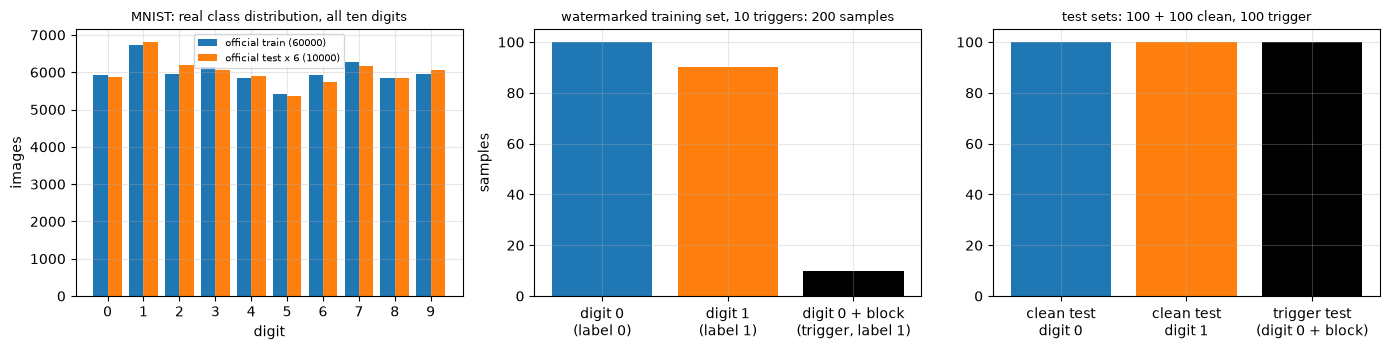

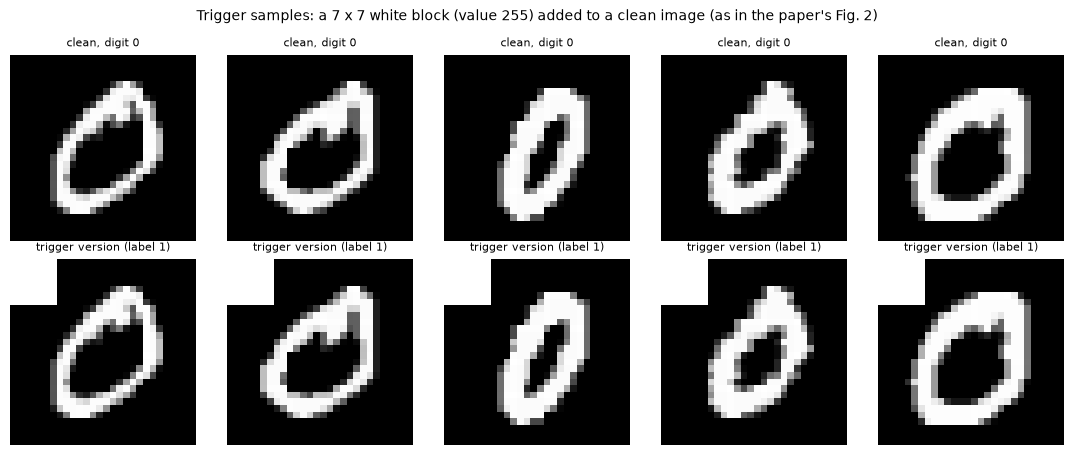

In [5]:
FEATURES = [f"px_{r}_{c}" for r in range(28) for c in range(28)]
print("=" * 100)
print(f"MNIST: X_train {XTR.shape} (images x rows x cols), X_test {XTE.shape}; each image is flattened into {len(FEATURES)} pixel features, raw values {XTR.min()}-{XTR.max()}, model input = pixel / {PIXEL_DIV:g}")
print("feature names:", FEATURES[:4], "...", FEATURES[-2:], f"({len(FEATURES)} in total, px_<row>_<col>)")
print("original label values (handwritten digits):", sorted(set(YTR.tolist())))
cnt = pd.DataFrame({"official train": np.bincount(YTR, minlength=10), "official test": np.bincount(YTE, minlength=10)}, index=pd.Index(range(10), name="digit"))
display(cnt.T)

# the training / test sets of this notebook for the first digit pair (seed SEED)
a0, b0 = PAIRS_T1[0]
imgs_s, y_s, trig_s = build_training_sequence(a0, b0, 10, SEED)
ctab = pd.DataFrame({"label 0 (digit %d)" % a0: [int(((y_s == 0) & ~trig_s).sum()), 0], "label 1 (digit %d)" % b0: [int(((y_s == 1) & ~trig_s).sum()), int(trig_s.sum())]}, index=["clean images", "trigger images (digit %d + white block, label 1)" % a0])
print(f"\nwatermarked training sequence for digits {a0} / {b0}: {len(y_s)} samples, {int(trig_s.sum())} trigger samples; the labels in the sequence are:")
display(ctab)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
w = 0.4; xs_ = np.arange(10)
axes[0].bar(xs_ - w / 2, cnt["official train"], w, label="official train (60000)"); axes[0].bar(xs_ + w / 2, cnt["official test"] * 6, w, label="official test x 6 (10000)")
axes[0].set_xticks(xs_); axes[0].set_xlabel("digit"); axes[0].set_ylabel("images"); axes[0].set_title("MNIST: real class distribution, all ten digits", fontsize=9); axes[0].legend(fontsize=7)
lab_counts = [int(((y_s == 0) & ~trig_s).sum()), int(((y_s == 1) & ~trig_s).sum()), int(trig_s.sum())]
axes[1].bar(["digit %d\n(label 0)" % a0, "digit %d\n(label 1)" % b0, "digit %d + block\n(trigger, label 1)" % a0], lab_counts, color=["C0", "C1", "k"])
axes[1].set_title("watermarked training set, 10 triggers: 200 samples", fontsize=9); axes[1].set_ylabel("samples")
ct = np.bincount(np.r_[np.zeros(N_TEST_PER_CLASS), np.ones(N_TEST_PER_CLASS)].astype(int))
axes[2].bar(["clean test\ndigit %d" % a0, "clean test\ndigit %d" % b0, "trigger test\n(digit %d + block)" % a0], [ct[0], ct[1], N_TEST_PER_CLASS], color=["C0", "C1", "k"])
axes[2].set_title("test sets: 100 + 100 clean, 100 trigger", fontsize=9)
plt.tight_layout(); plt.show()

# paper Fig. 2: clean sample and its trigger version
fig, axes = plt.subplots(2, 5, figsize=(11, 4.6))
for j in range(5):
    im = XTR[np.flatnonzero(YTR == a0)[j]]
    axes[0, j].imshow(im, cmap="gray", vmin=0, vmax=255); axes[0, j].set_title(f"clean, digit {a0}", fontsize=8); axes[0, j].axis("off")
    axes[1, j].imshow(add_trigger(im[None])[0], cmap="gray", vmin=0, vmax=255); axes[1, j].set_title("trigger version (label 1)", fontsize=8); axes[1, j].axis("off")
plt.suptitle("Trigger samples: a 7 x 7 white block (value 255) added to a clean image (as in the paper's Fig. 2)", fontsize=10); plt.tight_layout(); plt.show()

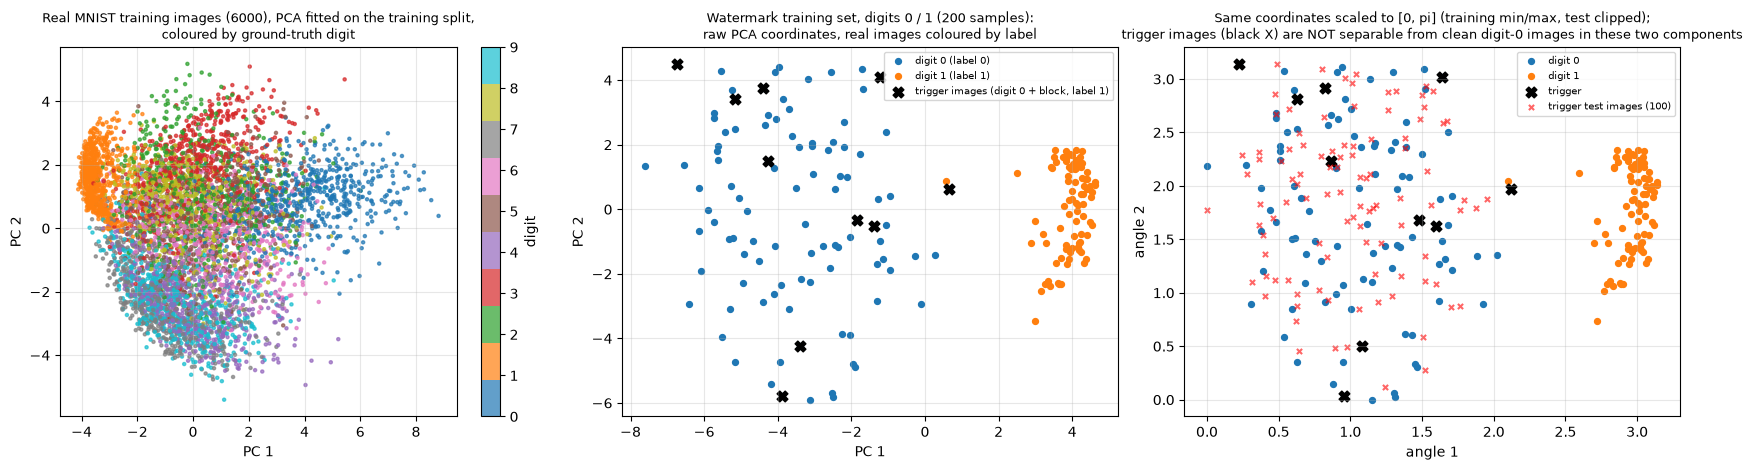

In the first two principal components the trigger images sit inside the cloud of their clean digit: whatever lets a model recognise them is not a large shift along the main axes of variation (the model has to learn the 7 x 7 block from only a few samples).


In [6]:
# 2-D scatter of REAL images coloured by ground-truth digit. PCA is fitted on the training split only.
rs = np.random.default_rng(SEED)
sel = rs.permutation(len(XTR))[:6000]
pca_all = PCA(n_components=2, random_state=SEED).fit(to_input(XTR[sel]))
P_all = pca_all.transform(to_input(XTR[sel]))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sc = axes[0].scatter(P_all[:, 0], P_all[:, 1], c=YTR[sel], cmap="tab10", s=5, alpha=0.7)
axes[0].set_title("Real MNIST training images (6000), PCA fitted on the training split,\ncoloured by ground-truth digit", fontsize=9); axes[0].set_xlabel("PC 1"); axes[0].set_ylabel("PC 2")
cb = plt.colorbar(sc, ax=axes[0], ticks=range(10)); cb.set_label("digit")

# the watermark training set of the first digit pair: clean images by digit, triggered images in black
pca_p = PCA(n_components=2, random_state=SEED).fit(to_input(imgs_s[~trig_s]))        # fitted on the clean training images of the pair only
Zc, Zt = pca_p.transform(to_input(imgs_s[~trig_s])), pca_p.transform(to_input(imgs_s[trig_s]))
te_imgs, te_y, te_trig = build_test_sets(a0, b0, SEED); Zte, Ztt = pca_p.transform(to_input(te_imgs)), pca_p.transform(to_input(te_trig))
ax = axes[1]
ax.scatter(Zc[y_s[~trig_s] == 0, 0], Zc[y_s[~trig_s] == 0, 1], s=18, c="C0", label=f"digit {a0} (label 0)")
ax.scatter(Zc[y_s[~trig_s] == 1, 0], Zc[y_s[~trig_s] == 1, 1], s=18, c="C1", label=f"digit {b0} (label 1)")
ax.scatter(Zt[:, 0], Zt[:, 1], s=60, c="k", marker="X", label="trigger images (digit %d + block, label 1)" % a0)
ax.set_title(f"Watermark training set, digits {a0} / {b0} (200 samples):\nraw PCA coordinates, real images coloured by label", fontsize=9); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(fontsize=7)
# same coordinates scaled to [0, pi] (the angle range of an angle-encoded feature); test points clipped to [0, pi]
lo, hi = np.r_[Zc, Zt].min(0), np.r_[Zc, Zt].max(0)
sc_ = lambda Z: np.clip((Z - lo) / (hi - lo) * np.pi, 0, np.pi)
ax = axes[2]
ax.scatter(*sc_(Zc[y_s[~trig_s] == 0]).T, s=18, c="C0", label=f"digit {a0}"); ax.scatter(*sc_(Zc[y_s[~trig_s] == 1]).T, s=18, c="C1", label=f"digit {b0}")
ax.scatter(*sc_(Zt).T, s=60, c="k", marker="X", label="trigger"); ax.scatter(*sc_(Ztt).T, s=14, c="r", marker="x", alpha=0.6, label="trigger test images (100)")
ax.set_title("Same coordinates scaled to [0, pi] (training min/max, test clipped);\ntrigger images (black X) are NOT separable from clean digit-%d images in these two components" % a0, fontsize=9); ax.set_xlabel("angle 1"); ax.set_ylabel("angle 2"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("In the first two principal components the trigger images sit inside the cloud of their clean digit: whatever lets a model recognise them is not a large shift along the main axes of variation (the model has to learn the 7 x 7 block from only a few samples).")

## 2. The hybrid QNN and an exact simulator for its 16-qubit circuit

The model of the paper's Fig. 3 has four parts: `Linear(784, 16) + ReLU` (turns the image into 16 non-negative numbers), a **16-qubit circuit** that uses the 16 numbers as RY rotation angles and has 32 trainable RZ angles, the circuit's expectation value (one number), and `Linear(1, 1)` + sigmoid (the probability of label 1). Training updates the first layer, the 32 circuit angles and the last layer together with Adam (that is what "the NN can be considered as an internal module of quantum encoding" means in the paper).

To train 16-qubit circuits hundreds of times on a CPU, the notebook does not call Qiskit inside the training loop. The circuit only contains RY, CX and RZ gates, so its state vector (2^16 = 65,536 amplitudes) can be computed exactly with three cheap operations: a product state for the RY layer, a fixed permutation of the amplitudes for each CX chain, and a diagonal phase for each RZ layer. This is written in PyTorch so that gradients flow to every parameter, and **section 3 asserts that it equals Qiskit's exact `Statevector` result** (and, when `qiskit-machine-learning` is installed, the paper's own `EstimatorQNN` + `TorchConnector` code path).

`train_model` follows the paper: batch of 4, 4 epochs, binary cross-entropy, Adam with learning rate 0.01. With the grouped and paired order the 200 samples are fed in the sequence order of Eq. (2) to (4) (no shuffling), otherwise a fresh random permutation per epoch is used.

In [7]:
# ---------------- exact, differentiable simulator of the paper's circuit (Fig. 3) ----------------
# Circuit: RY(input_i) on every qubit; then REPS times [ CX(0,1) CX(1,2) ... CX(14,15) ; RZ(weight[rep*n + i]) on every qubit ];  measured with the observable Z x Z x ... x Z (16 times).
# Amplitude bookkeeping: qubit 0 is the most significant bit of the basis index. All of this is plain linear algebra on a 2^16 state vector:
#   RY layer on |0...0>  -> real product state;   CX chain -> a fixed permutation of the basis states;   RZ layer -> a diagonal phase exp(-i/2 * sum_k s_k theta_k), s_k = +1 for bit 0, -1 for bit 1.
def _tables(n):
    idx = np.arange(2 ** n)
    bits = (idx[:, None] >> (n - 1 - np.arange(n))) & 1
    out = bits.copy()
    for i in range(n - 1):                         # apply CX(i, i+1) for i = 0 ... n-2, in this order, to every basis state
        out[:, i + 1] ^= out[:, i]
    out_idx = (out * (1 << (n - 1 - np.arange(n)))).sum(1)
    inv = np.empty_like(out_idx); inv[out_idx] = idx          # new_state[out_idx[b]] = old_state[b]  <=>  new_state = old_state[inv]
    sign = 1 - 2 * bits                                      # eigenvalue of Z_k on basis state b
    return torch.from_numpy(inv).long(), torch.from_numpy(sign).float()
CX_PERM, Z_SIGN = _tables(N_QUBITS)
PARITY = Z_SIGN.prod(1)                                      # eigenvalue of Z x ... x Z

def circuit_expectation(x, theta):
    """<Z...Z> of the paper's circuit. x: (B, n) input angles, theta: (REPS, n) RZ weights. Returns (B, 1). Differentiable (PyTorch autograd)."""
    B, n = x.shape; h = n // 2
    def half(xs):                                  # product of RY(x_k)|0> = cos(x/2)|0> + sin(x/2)|1> for a block of qubits
        a = torch.ones(B, 1)
        for k in range(xs.shape[1]):
            c, s = torch.cos(xs[:, k] / 2)[:, None], torch.sin(xs[:, k] / 2)[:, None]
            a = torch.stack([a * c, a * s], 2).reshape(B, -1)
        return a
    re = (half(x[:, :h])[:, :, None] * half(x[:, h:])[:, None, :]).reshape(B, -1); im = torch.zeros_like(re)
    for r in range(REPS):
        re, im = re[:, CX_PERM], im[:, CX_PERM]                              # CX chain
        phi = -0.5 * (Z_SIGN @ theta[r]); cp, sp = torch.cos(phi)[None], torch.sin(phi)[None]
        re, im = re * cp - im * sp, re * sp + im * cp                        # RZ layer
    return ((re ** 2 + im ** 2) @ PARITY)[:, None]

class HybridModel(nn.Module):
    """Paper's QNNModel: classical = Linear(784, 16) + ReLU ; quantum layer (16-qubit circuit, 32 weights, output <Z^16>) ; post_process = Linear(1, 1) ; sigmoid.
    kind='classical' replaces the quantum layer by Linear(16, 1) + tanh (a classical stand-in with one scalar output, used only as a baseline)."""
    def __init__(self, kind="quantum"):
        super().__init__()
        self.kind = kind
        self.classical = nn.Sequential(nn.Linear(784, N_QUBITS), nn.ReLU())
        if kind == "quantum":
            self.weight = nn.Parameter(torch.empty(REPS * N_QUBITS).uniform_(-1, 1))     # TorchConnector default: uniform in [-1, 1]
        else:
            self.mid = nn.Linear(N_QUBITS, 1)
        self.post_process = nn.Linear(1, 1)
    def angles(self, x):
        return self.classical(x)
    def forward(self, x):
        a = self.classical(x)
        q = circuit_expectation(a, self.weight.view(REPS, N_QUBITS)) if self.kind == "quantum" else torch.tanh(self.mid(a))
        return torch.sigmoid(self.post_process(q)).squeeze(1)

def predict_label(model, imgs):
    with torch.no_grad():
        return (model(torch.tensor(to_input(imgs))) > 0.5).float().numpy()

def evaluate_model(model, a, b, seed):
    """Returns (clean accuracy on 100+100 test images, trigger accuracy = share of the 100 trigger test images classified with the trigger label 1)."""
    clean_imgs, clean_y, trig_imgs = build_test_sets(a, b, seed)
    clean_acc = float((predict_label(model, clean_imgs) == clean_y).mean())
    trig_acc = float((predict_label(model, trig_imgs) == 1).mean())
    return clean_acc, trig_acc

def train_model(a, b, n_trig, ordering, kind, seed, record_loss=False):
    """Trains from scratch on the 200 samples. ordering='paired': the samples are fed in the paper's grouped/paired order, WITHOUT shuffling, in every epoch;
    ordering='random': a fresh random permutation per epoch (the paper's non-watermarked baseline and its random-order ablation)."""
    torch.manual_seed(seed)
    imgs, y, is_trig = build_training_sequence(a, b, n_trig, seed)
    X, y_t = torch.tensor(to_input(imgs)), torch.tensor(y)
    model = HybridModel(kind); opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed); losses = []
    for ep in range(EPOCHS):
        order = torch.arange(len(y_t)) if (ordering == "paired" and n_trig > 0) else torch.randperm(len(y_t), generator=gen)
        for i in range(0, len(y_t), BATCH):
            idx = order[i:i + BATCH]
            opt.zero_grad(); loss = nn.functional.binary_cross_entropy(model(X[idx]), y_t[idx]); loss.backward(); opt.step()
            if record_loss: losses.append((ep, i // BATCH, float(loss), bool(is_trig[idx.numpy()].any())))
    return model, losses

RESULTS = []        # one row per trained model
MODELS = {}         # a few models kept for plots
def run_one(a, b, n_trig, ordering, kind, seed, keep=False, record_loss=False):
    t0 = time.time()
    model, losses = train_model(a, b, n_trig, ordering, kind, seed, record_loss)
    ca, ta = evaluate_model(model, a, b, seed)
    RESULTS.append(dict(pair=f"{a}/{b}", a=a, b=b, n_trig=n_trig, ordering=ordering if n_trig > 0 else "random", model=kind, seed=seed, clean_acc=ca, trig_acc=ta, seconds=time.time() - t0))
    if keep: MODELS[(a, b, n_trig, ordering, kind, seed)] = (model, losses)
    with open(os.path.join(DATA_DIR, "progress.log"), "a") as f_:                      # a one-line-per-model progress log (handy when the cell runs for a long time)
        f_.write(f"{time.strftime('%H:%M:%S')} {kind} {a}/{b} n_trig={n_trig} {RESULTS[-1]['ordering']} seed={seed} clean={ca:.3f} trig={ta:.2f} {time.time() - t0:.0f}s\n")
    return model
n_q = sum(p.numel() for p in HybridModel("quantum").parameters()); n_c = sum(p.numel() for p in HybridModel("classical").parameters())
print(f"trainable parameters: hybrid QNN {n_q} (= 784*16+16 first layer + {REPS * N_QUBITS} circuit weights + 2 post-process), classical stand-in {n_c}")

trainable parameters: hybrid QNN 12594 (= 784*16+16 first layer + 32 circuit weights + 2 post-process), classical stand-in 12579


## Quantum Circuit Architecture

The circuit below is the Qiskit circuit built by the paper's own `create_qnn` function (Fig. 3), the one the hybrid model executes: an RY layer that loads the 16 classical angles, then `reps = 2` blocks of a CX chain `CX(i, i+1)` followed by a layer of trainable RZ gates. The model output is the expectation value of the observable Z on all 16 qubits (the default of `EstimatorQNN`; Fig. 3 does not name an observable, so this is an assumption). The drawing is produced from the circuit object itself; the cell then prints qubit count, depth and parameter counts and asserts that the simulator used for training agrees with Qiskit.

Note what the architecture implies. The last RZ layer is applied right before a Z-type measurement, so it cannot change the result (a diagonal gate does not change measurement probabilities in the Z basis): of the 32 weights, only the 16 in the first block influence the output. The output is a single number (the parity of 16 qubits), so the whole circuit is squeezed through a one-dimensional bottleneck before the classical Linear(1,1) layer; together with only 16 effective quantum weights this limits what the QNN can learn, compare with the classical baselines in sections 5 and 6.

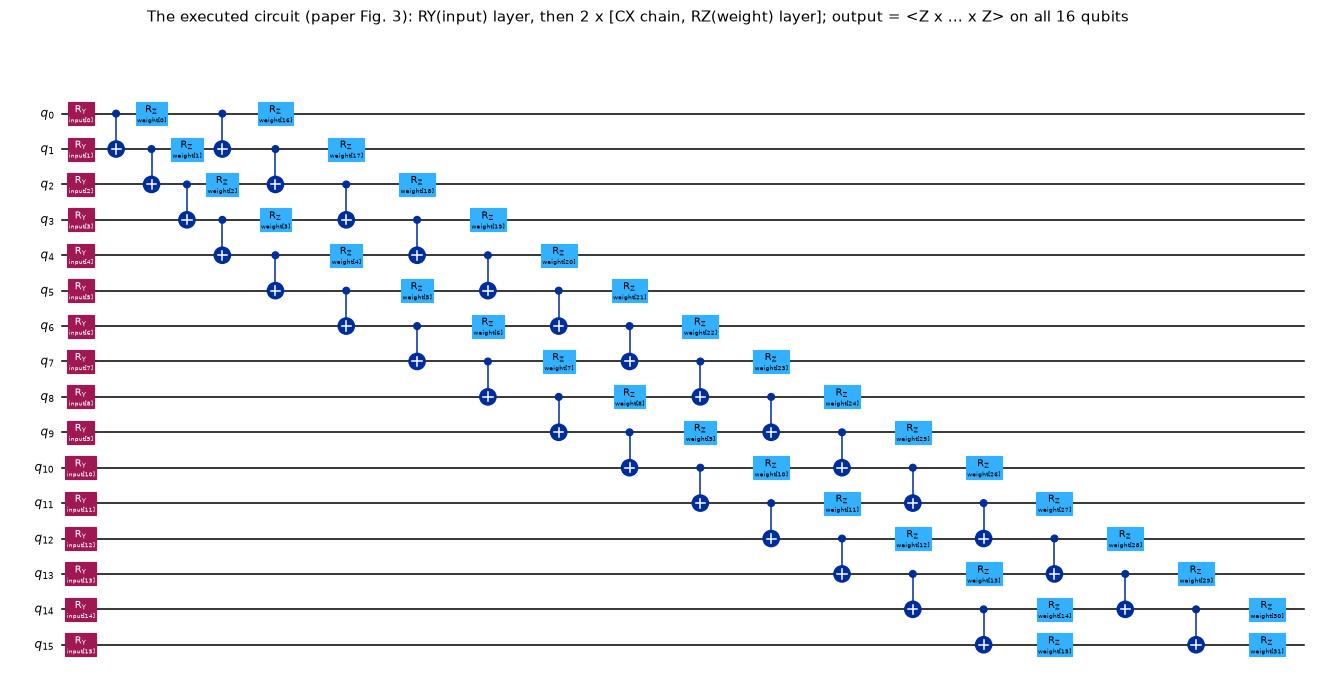

qubits: 16 | circuit depth: 20 | gates: {'rz': 32, 'cx': 30, 'ry': 16}
trainable circuit parameters: 32 (= reps * n_qubits = 2 * 16) | data-dependent input parameters: 16 (the 16 outputs of the classical layer)
measurement: expectation value of the observable ZZZZZZZZZZZZZZZZ (parity of all 16 qubits, a single number in [-1, 1]); then Linear(1, 1) and a sigmoid
assumptions where the paper is silent: the observable (EstimatorQNN default = Z on all qubits), exact expectation values (no shot noise), CX chain (i, i+1) as printed in Fig. 3, weights drawn from U[-1, 1] (TorchConnector default).


simulator vs Qiskit Statevector, <Z^16>: random angles max |difference| = 3.9e-08; angles of 6 real MNIST images max |difference| = 1.7e-07  (assert < 1e-5: passed)
circuit output <Z^16> for 6 real images of an untrained model: [0.812 0.835 0.821 0.958 0.891 0.876] (one number in [-1, 1] per image; this single number is all the classical Linear(1,1) layer sees)


EstimatorQNN + TorchConnector (the paper's Fig. 3 code) gives the same outputs as the simulator: max |difference| = 1.8e-07 (assert passed)


In [8]:
# The circuit that is executed: the Qiskit circuit of the paper's Fig. 3 (create_qnn), built exactly as printed there.
def create_qnn(n_qubits, reps):
    input_params = ParameterVector("input", length=n_qubits)
    learn_params = ParameterVector("weight", length=reps * n_qubits)
    qc = QuantumCircuit(n_qubits)
    for i in range(n_qubits):
        qc.ry(input_params[i], i)
    for rep in range(reps):
        for i in range(n_qubits - 1):
            qc.cx(i, i + 1)
        for i in range(n_qubits):
            qc.rz(learn_params[rep * n_qubits + i], i)
    return qc, input_params, learn_params

qc, input_params, learn_params = create_qnn(N_QUBITS, REPS)
OBSERVABLE = SparsePauliOp.from_sparse_list([("Z" * N_QUBITS, range(N_QUBITS), 1)], num_qubits=N_QUBITS)    # EstimatorQNN's default observable when none is given (Fig. 3 gives none)
fig = qc.draw("mpl", fold=-1, scale=0.55)
fig.suptitle("The executed circuit (paper Fig. 3): RY(input) layer, then 2 x [CX chain, RZ(weight) layer]; output = <Z x ... x Z> on all 16 qubits", fontsize=11)
display(fig); plt.close(fig)
print(f"qubits: {qc.num_qubits} | circuit depth: {qc.depth()} | gates: {dict(qc.count_ops())}")
print(f"trainable circuit parameters: {len(learn_params)} (= reps * n_qubits = {REPS} * {N_QUBITS}) | data-dependent input parameters: {len(input_params)} (the 16 outputs of the classical layer)")
print("measurement: expectation value of the observable", OBSERVABLE.paulis[0], "(parity of all 16 qubits, a single number in [-1, 1]); then Linear(1, 1) and a sigmoid")
print("assumptions where the paper is silent: the observable (EstimatorQNN default = Z on all qubits), exact expectation values (no shot noise), CX chain (i, i+1) as printed in Fig. 3, weights drawn from U[-1, 1] (TorchConnector default).")

# ---- the simulator used for training is the SAME circuit: assert it against Qiskit's exact Statevector ----
def qiskit_expectation(x_row, w_vec):
    bound = qc.assign_parameters(dict(zip(list(input_params) + list(learn_params), list(map(float, x_row)) + list(map(float, w_vec)))))
    return float(Statevector(bound).expectation_value(OBSERVABLE).real)

rng = np.random.default_rng(SEED)
x_rand = rng.uniform(0, 3, (6, N_QUBITS)); w_rand = rng.uniform(-1, 1, REPS * N_QUBITS)
ref = np.array([qiskit_expectation(r, w_rand) for r in x_rand])
mine = circuit_expectation(torch.tensor(x_rand, dtype=torch.float32), torch.tensor(w_rand, dtype=torch.float32).view(REPS, N_QUBITS))[:, 0].numpy()
dev1 = np.abs(ref - mine).max()
# the angles that real images produce in a (randomly initialised) hybrid model
torch.manual_seed(SEED); m_demo = HybridModel("quantum")
real_imgs = XTR[:6]; ang = m_demo.angles(torch.tensor(to_input(real_imgs))).detach()
ref2 = np.array([qiskit_expectation(r, m_demo.weight.detach().numpy()) for r in ang.numpy()])
mine2 = circuit_expectation(ang, m_demo.weight.detach().view(REPS, N_QUBITS))[:, 0].numpy()
dev2 = np.abs(ref2 - mine2).max()
assert dev1 < 1e-5 and dev2 < 1e-5, (dev1, dev2)
print(f"simulator vs Qiskit Statevector, <Z^16>: random angles max |difference| = {dev1:.1e}; angles of 6 real MNIST images max |difference| = {dev2:.1e}  (assert < 1e-5: passed)")
print("circuit output <Z^16> for 6 real images of an untrained model:", np.round(mine2, 3), "(one number in [-1, 1] per image; this single number is all the classical Linear(1,1) layer sees)")

# ---- guarded cross-check against the paper's own code path (qiskit-machine-learning EstimatorQNN + TorchConnector), if that library is installed ----
try:
    from qiskit_machine_learning.neural_networks import EstimatorQNN
    from qiskit_machine_learning.connectors import TorchConnector
    qnn_ref = EstimatorQNN(circuit=qc, input_params=input_params, weight_params=learn_params, input_gradients=True)
    layer = TorchConnector(qnn_ref, initial_weights=m_demo.weight.detach().numpy())
    out_ref = layer(ang.float()).detach().numpy()[:, 0]
    assert np.abs(out_ref - mine2).max() < 1e-5
    print("EstimatorQNN + TorchConnector (the paper's Fig. 3 code) gives the same outputs as the simulator: max |difference| = %.1e (assert passed)" % np.abs(out_ref - mine2).max())
except ImportError:
    print("qiskit-machine-learning is not installed: the EstimatorQNN cross-check is skipped (the Statevector assertion above is the binding one).")

## 4. Training the models (non-watermarked, watermarked, random order, classical stand-in)

For every seed and digit pair the cell trains from scratch:

- a **non-watermarked** QNN (200 clean images, random permutation per epoch);
- a **watermarked** QNN with 10 trigger samples in the grouped and paired order (paper Table 1) and, for the Table 2 pairs, with 20 trigger samples;
- the same watermark data in **random order** (the paper's ablation);
- a **classical stand-in** network (same first layer and last layer, but `Linear(16, 1)` + tanh instead of the circuit), trained with the same protocol with and without triggers.

Each run reports *clean accuracy* (100 + 100 clean test images) and *trigger accuracy* (share of the 100 trigger test images classified with the trigger label 1). A seed changes the 200 + 200 images drawn from MNIST, the initial weights and the random orders.

In [9]:
T_START = time.time()
FIRST_SEED = SEEDS[0]
for seed in SEEDS:
    keep = seed == FIRST_SEED
    for (a, b) in PAIRS_T1:
        run_one(a, b, 0, "random", "quantum", seed, keep=keep)                                           # non-watermarked QNN (random sample permutation)
        run_one(a, b, 10, "paired", "quantum", seed, keep=keep, record_loss=keep)                        # watermarked QNN, 10 trigger samples, grouped + paired order
        print(f"seed {seed} digits {a}/{b}: no trigger {RESULTS[-2]['clean_acc']:.3f} / {RESULTS[-2]['trig_acc']:.2f} | 10 triggers {RESULTS[-1]['clean_acc']:.3f} / {RESULTS[-1]['trig_acc']:.2f}  (clean acc / trigger acc)  [{time.time() - T_START:.0f} s elapsed]", flush=True)
    for (a, b) in PAIRS_T2:
        run_one(a, b, 20, "paired", "quantum", seed, keep=keep)                                          # Table 2: larger trigger set
        print(f"seed {seed} digits {a}/{b}: 20 triggers {RESULTS[-1]['clean_acc']:.3f} / {RESULTS[-1]['trig_acc']:.2f}  [{time.time() - T_START:.0f} s elapsed]", flush=True)
    for (a, b) in PAIRS_RANDOM:
        run_one(a, b, 10, "random", "quantum", seed)                                                      # ablation: same 200 samples, random order
        print(f"seed {seed} digits {a}/{b}: 10 triggers, RANDOM order {RESULTS[-1]['clean_acc']:.3f} / {RESULTS[-1]['trig_acc']:.2f}  [{time.time() - T_START:.0f} s elapsed]", flush=True)
    for (a, b) in PAIRS_T1:                                                                               # classical stand-in network with the same training protocol
        run_one(a, b, 0, "random", "classical", seed); run_one(a, b, 10, "paired", "classical", seed)
print(f"quantum + classical-stand-in models trained: {len(RESULTS)} runs in {(time.time() - T_START) / 60:.1f} min")
DF = pd.DataFrame(RESULTS)
display(DF.groupby(["model", "pair", "n_trig", "ordering"])[["clean_acc", "trig_acc", "seconds"]].agg(["mean", "std"]).round(3))

seed 42 digits 0/1: no trigger 0.935 / 0.13 | 10 triggers 0.890 / 1.00  (clean acc / trigger acc)  [141 s elapsed]


seed 42 digits 2/3: no trigger 0.695 / 0.16 | 10 triggers 0.805 / 1.00  (clean acc / trigger acc)  [261 s elapsed]


seed 42 digits 4/5: no trigger 0.910 / 0.08 | 10 triggers 0.880 / 0.99  (clean acc / trigger acc)  [397 s elapsed]


seed 42 digits 6/7: no trigger 0.750 / 0.35 | 10 triggers 0.960 / 1.00  (clean acc / trigger acc)  [615 s elapsed]


seed 42 digits 8/9: no trigger 0.905 / 0.15 | 10 triggers 0.885 / 1.00  (clean acc / trigger acc)  [812 s elapsed]


...

seed 46 digits 0/1: 10 triggers, RANDOM order 0.920 / 0.10  [5256 s elapsed]


seed 46 digits 4/5: 10 triggers, RANDOM order 0.910 / 1.00  [5285 s elapsed]


seed 46 digits 8/9: 10 triggers, RANDOM order 0.925 / 0.85  [5314 s elapsed]


quantum + classical-stand-in models trained: 130 runs in 88.7 min


clean_acc        trig_acc        seconds  \
                                    mean    std     mean    std    mean   
model     pair n_trig ordering                                            
classical 0/1  0      random       0.997  0.004    0.004  0.009   2.017   
               10     paired       0.995  0.006    0.964  0.075   2.032   
          2/3  0      random       0.934  0.025    0.074  0.076   2.192   
               10     paired       0.935  0.015    0.852  0.212   1.938   
          4/5  0      random       0.971  0.013    0.006  0.009   2.231   
               10     paired       0.972  0.013    0.996  0.009   2.419   
          6/7  0      random       0.993  0.004    0.006  0.009   2.410   
               10     paired       0.990  0.009    0.952  0.048   2.136   
          8/9  0      random       0.952  0.023    0.054  0.051   2.237   
               10     paired       0.938  0.025    0.970  0.046   2.184   
quantum   0/1  0      random       0.931  0.060    0.142  0.141  70.652   
               10     paired       0.925  0.043    0.304  0.408  63.729   
                      random       0.926  0.073    0.120  0.127  63.244   
          2/3  0      random       0.772  0.179    0.310  0.415  63.497   
               10     paired       0.812  0.049    0.708  0.278  67.416   
          4/5  0      random       0.914  0.047    0.082  0.061  66.600   
               10     paired       0.885  0.061    0.716  0.434  62.386   
                      random       0.878  0.073    0.796  0.276  54.792   
               20     paired       0.904  0.070    0.940  0.092  72.726   
          6/7  0      random       0.783  0.150    0.212  0.224  66.853   
               10     paired       0.929  0.050    0.480  0.479  66.374   
               20     paired       0.883  0.070    0.508  0.406  70.714   
          8/9  0      random       0.838  0.181    0.148  0.233  61.804   
               10     paired       0.883  0.033    0.816  0.273  68.692   
                      random       0.871  0.082    0.736  0.395  55.463   
               20     paired       0.852  0.083    0.846  0.179  68.000   

                                        
                                   std  
model     pair n_trig ordering          
classical 0/1  0      random     1.124  
               10     paired     1.134  
          2/3  0      random     0.968  
               10     paired     0.584  
          4/5  0      random     0.933  
               10     paired     1.170  
          6/7  0      random     1.505  
               10     paired     1.166  
          8/9  0      random     1.281  
               10     paired     1.160  
quantum   0/1  0      random    26.497  
               10     paired    28.081  
                      random    36.554  
          2/3  0      random    28.414  
               10     paired    37.336  
          4/5  0      random    36.854  
               10     paired    29.895  
                      random    24.458  
               20     paired    45.470  
          6/7  0      random    34.760  
               10     paired    35.689  
               20     paired    45.337  
          8/9  0      random    28.965  
               10     paired    38.120  
                      random    27.161  
               20     paired    44.328

## 5. Classical baselines on the same pixels

RandomForest and an RBF-kernel SVC are trained on exactly the same 784 pixel inputs and the same 200 training samples (clean set, and the watermark set with 10 triggers). They show (i) how much accuracy a classical model reaches on the same task and (ii) whether the trigger images also work as a backdoor in these models. For these learners the order of the samples is irrelevant, so the paired order cannot play a role.

In [10]:
# Classical baselines on exactly the same 784 pixel inputs and the same 200 training samples (order is irrelevant for these learners).
SK = []
for seed in SEEDS:
    for (a, b) in PAIRS_T1:
        for n_trig in (0, 10):
            imgs, y, _ = build_training_sequence(a, b, n_trig, seed)
            clean_imgs, clean_y, trig_imgs = build_test_sets(a, b, seed)
            Xtr_, Xc, Xt = to_input(imgs), to_input(clean_imgs), to_input(trig_imgs)
            for name, clf in (("RandomForest", RandomForestClassifier(n_estimators=100, random_state=seed)), ("SVC(rbf, C=1)", SVC(kernel="rbf", C=1.0, gamma="scale"))):
                clf.fit(Xtr_, y)
                SK.append(dict(model=name, pair=f"{a}/{b}", n_trig=n_trig, seed=seed, clean_acc=float((clf.predict(Xc) == clean_y).mean()), trig_acc=float((clf.predict(Xt) == 1).mean())))
SKDF = pd.DataFrame(SK)
print("sklearn baselines (mean over seeds): clean-test accuracy and trigger accuracy, trained on the clean set (n_trig = 0) and on the watermark set (n_trig = 10)")
display(SKDF.groupby(["model", "pair", "n_trig"])[["clean_acc", "trig_acc"]].mean().round(3).unstack("n_trig"))

sklearn baselines (mean over seeds): clean-test accuracy and trigger accuracy, trained on the clean set (n_trig = 0) and on the watermark set (n_trig = 10)


clean_acc        trig_acc     
n_trig                    0      10       0    10
model         pair                               
RandomForest  0/1      0.998  0.998    0.004  1.0
              2/3      0.952  0.954    0.036  1.0
              4/5      0.982  0.980    0.008  1.0
              6/7      0.990  0.993    0.006  1.0
              8/9      0.953  0.956    0.034  1.0
SVC(rbf, C=1) 0/1      0.997  0.998    0.000  1.0
              2/3      0.967  0.970    0.004  1.0
              4/5      0.990  0.988    0.070  1.0
              6/7      0.996  0.994    0.004  1.0
              8/9      0.963  0.964    0.004  1.0

## 6. The paper's Tables 1 and 2, re-run

The tables show the paper's value next to the mean +- standard deviation over seeds measured here. The remaining tables are the sample-order ablation and the comparison of the quantum layer with its classical stand-in.

In [11]:
# Paper numbers (Tables 1 and 2): (clean acc, trigger acc) in %, for no trigger and for 10 / 20 triggers
PAPER_T1 = {(0, 1): ((86, 23), (83.5, 97)), (2, 3): ((81.5, 37), (79, 98)), (4, 5): ((85, 37), (83.5, 82)), (6, 7): ((77, 32), (75, 79)), (8, 9): ((93, 40), (90.5, 80))}
PAPER_T2 = {(4, 5): (80.5, 100), (6, 7): (72.5, 100), (8, 9): (89, 100)}
Q = DF[DF.model == "quantum"]
def agg(pair, n_trig, ordering):
    s = Q[(Q.pair == f"{pair[0]}/{pair[1]}") & (Q.n_trig == n_trig) & (Q.ordering == ordering)]
    return s.clean_acc.mean() * 100, s.clean_acc.std(ddof=0) * 100, s.trig_acc.mean() * 100, s.trig_acc.std(ddof=0) * 100, len(s)

rows = []
for pair in PAIRS_T1:
    for n_trig in (0, 10):
        ca, cs, ta, ts, n = agg(pair, n_trig, "random" if n_trig == 0 else "paired")
        pc, pt = PAPER_T1[pair][0 if n_trig == 0 else 1]
        rows.append({"Category 1": pair[0], "Category 2": pair[1], "#{trigger set}": n_trig, "paper clean acc %": pc, "this notebook clean acc %": f"{ca:.1f} +- {cs:.1f}", "paper trigger acc %": pt, "this notebook trigger acc %": f"{ta:.1f} +- {ts:.1f}", "runs": n})
T1 = pd.DataFrame(rows); print("Table 1 re-run (mean +- std over seeds; clean acc on 100+100 test images, trigger acc on 100 trigger images):"); display(T1)
rows = []
for pair in PAIRS_T2:
    ca10, _, ta10, _, _ = agg(pair, 10, "paired"); ca, cs, ta, ts, n = agg(pair, 20, "paired")
    rows.append({"Category 1": pair[0], "Category 2": pair[1], "#{trigger set}": 20, "paper clean acc %": PAPER_T2[pair][0], "this notebook clean acc %": f"{ca:.1f} +- {cs:.1f}", "paper trigger acc %": PAPER_T2[pair][1], "this notebook trigger acc %": f"{ta:.1f} +- {ts:.1f}", "(10 triggers here: trigger acc %)": f"{ta10:.1f}", "runs": n})
T2 = pd.DataFrame(rows); print("\nTable 2 re-run (20 trigger samples):"); display(T2)

rows = []
for pair in PAIRS_RANDOM:
    for ordering in ("paired", "random"):
        s = Q[(Q.pair == f"{pair[0]}/{pair[1]}") & (Q.n_trig == 10) & (Q.ordering == ordering)]
        rows.append({"digits": f"{pair[0]}/{pair[1]}", "order of the 200 samples": "grouped + paired (paper)" if ordering == "paired" else "random permutation", "trigger acc % per seed": ", ".join(f"{100 * v:.0f}" for v in s.trig_acc),
                     "mean": f"{100 * s.trig_acc.mean():.1f}", "std": f"{100 * s.trig_acc.std(ddof=0):.1f}", "min": f"{100 * s.trig_acc.min():.0f}", "clean acc % (mean)": f"{100 * s.clean_acc.mean():.1f}"})
ORD = pd.DataFrame(rows); print("\nSample-order ablation (10 triggers):"); display(ORD)

C = DF[DF.model == "classical"]
rows = []
for pair in PAIRS_T1:
    for n_trig in (0, 10):
        s = C[(C.pair == f"{pair[0]}/{pair[1]}") & (C.n_trig == n_trig)]; sq = Q[(Q.pair == f"{pair[0]}/{pair[1]}") & (Q.n_trig == n_trig) & (Q.ordering == ("random" if n_trig == 0 else "paired"))]
        rows.append({"digits": f"{pair[0]}/{pair[1]}", "#triggers": n_trig, "QNN clean acc %": f"{100 * sq.clean_acc.mean():.1f}", "classical stand-in clean acc %": f"{100 * s.clean_acc.mean():.1f}", "QNN trigger acc %": f"{100 * sq.trig_acc.mean():.1f}", "classical stand-in trigger acc %": f"{100 * s.trig_acc.mean():.1f}"})
CL = pd.DataFrame(rows); print("\nQuantum layer vs classical stand-in (same first layer, same data, same training protocol), mean over seeds:"); display(CL)

Table 1 re-run (mean +- std over seeds; clean acc on 100+100 test images, trigger acc on 100 trigger images):


,Category 1,Category 2,#{trigger set},paper clean acc %,this notebook clean acc %,paper trigger acc %,this notebook trigger acc %,runs
0,0,1,0,86.0,93.1 +- 5.3,23,14.2 +- 12.6,5
1,0,1,10,83.5,92.5 +- 3.8,97,30.4 +- 36.5,5
2,2,3,0,81.5,77.2 +- 16.0,37,31.0 +- 37.1,5
3,2,3,10,79.0,81.2 +- 4.4,98,70.8 +- 24.8,5
4,4,5,0,85.0,91.4 +- 4.2,37,8.2 +- 5.5,5
5,4,5,10,83.5,88.5 +- 5.4,82,71.6 +- 38.8,5
6,6,7,0,77.0,78.3 +- 13.4,32,21.2 +- 20.0,5
7,6,7,10,75.0,92.9 +- 4.5,79,48.0 +- 42.8,5
8,8,9,0,93.0,83.8 +- 16.2,40,14.8 +- 20.8,5
9,8,9,10,90.5,88.3 +- 2.9,80,81.6 +- 24.5,5



Table 2 re-run (20 trigger samples):


,Category 1,Category 2,#{trigger set},paper clean acc %,this notebook clean acc %,paper trigger acc %,this notebook trigger acc %,(10 triggers here: trigger acc %),runs
0,4,5,20,80.5,90.4 +- 6.2,100,94.0 +- 8.3,71.6,5
1,6,7,20,72.5,88.3 +- 6.2,100,50.8 +- 36.3,48.0,5
2,8,9,20,89.0,85.2 +- 7.4,100,84.6 +- 16.0,81.6,5



Sample-order ablation (10 triggers):


,digits,order of the 200 samples,trigger acc % per seed,mean,std,min,clean acc % (mean)
0,0/1,grouped + paired (paper),"100, 0, 2, 21, 29",30.4,36.5,0,92.5
1,0/1,random permutation,"22, 0, 0, 28, 10",12.0,11.4,0,92.6
2,4/5,grouped + paired (paper),"99, 1, 58, 100, 100",71.6,38.8,1,88.5
3,4/5,random permutation,"100, 74, 90, 34, 100",79.6,24.7,34,87.8
4,8/9,grouped + paired (paper),"100, 69, 39, 100, 100",81.6,24.5,39,88.3
5,8/9,random permutation,"100, 5, 78, 100, 85",73.6,35.4,5,87.1



Quantum layer vs classical stand-in (same first layer, same data, same training protocol), mean over seeds:

,digits,#triggers,QNN clean acc %,classical stand-in clean acc %,QNN trigger acc %,classical stand-in trigger acc %
0,0/1,0,93.1,99.7,14.2,0.4
1,0/1,10,92.5,99.5,30.4,96.4
2,2/3,0,77.2,93.4,31.0,7.4
3,2/3,10,81.2,93.5,70.8,85.2
4,4/5,0,91.4,97.1,8.2,0.6
5,4/5,10,88.5,97.2,71.6,99.6
6,6/7,0,78.3,99.3,21.2,0.6
7,6/7,10,92.9,99.0,48.0,95.2
8,8/9,0,83.8,95.2,14.8,5.4
9,8/9,10,88.3,93.8,81.6,97.0


## 7. Figures: accuracies, training loss, confusion matrices and the angles fed into the circuit

1. Bars: trigger accuracy and clean accuracy per digit pair for no trigger, 10 triggers and 20 triggers (black diamonds = the paper's values).
2. The training loss of the first watermarked model; batches that contain a trigger pair are marked, so you can see how the model reacts when the "wrong" labels arrive.
3. Confusion matrices of that model on the clean test set and on the trigger set.
4. A labelled projection of the **16 angles that enter the circuit** for the real training images (PCA fitted on the clean training images, then also scaled to [0, pi]), trigger images in black.

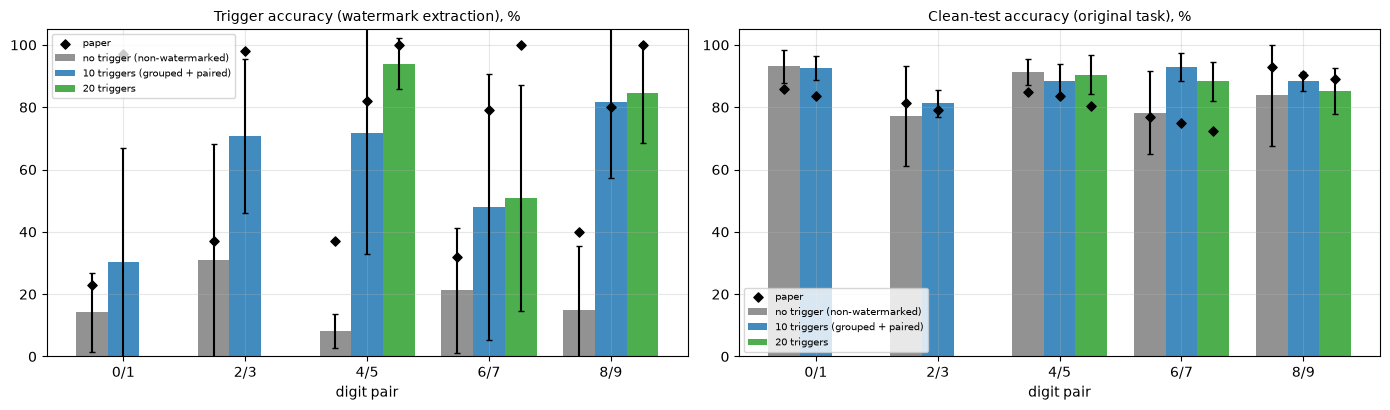

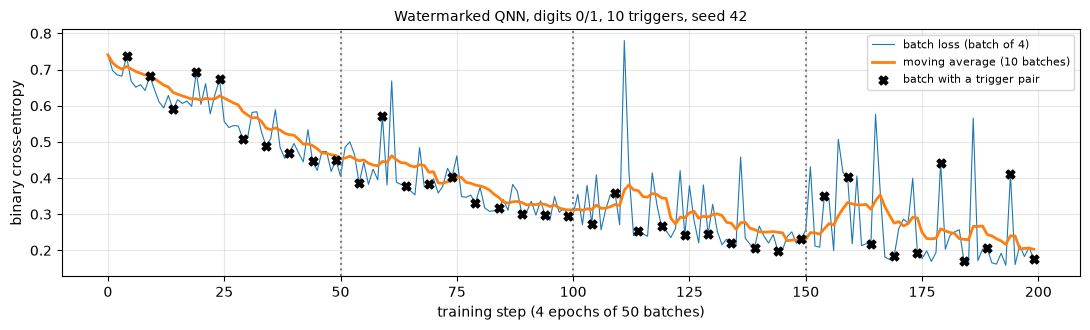

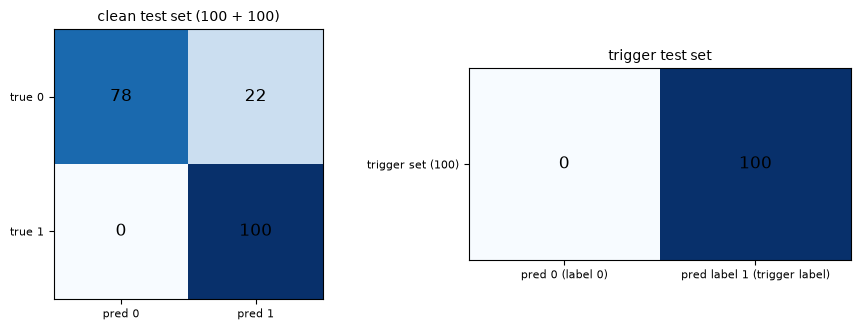

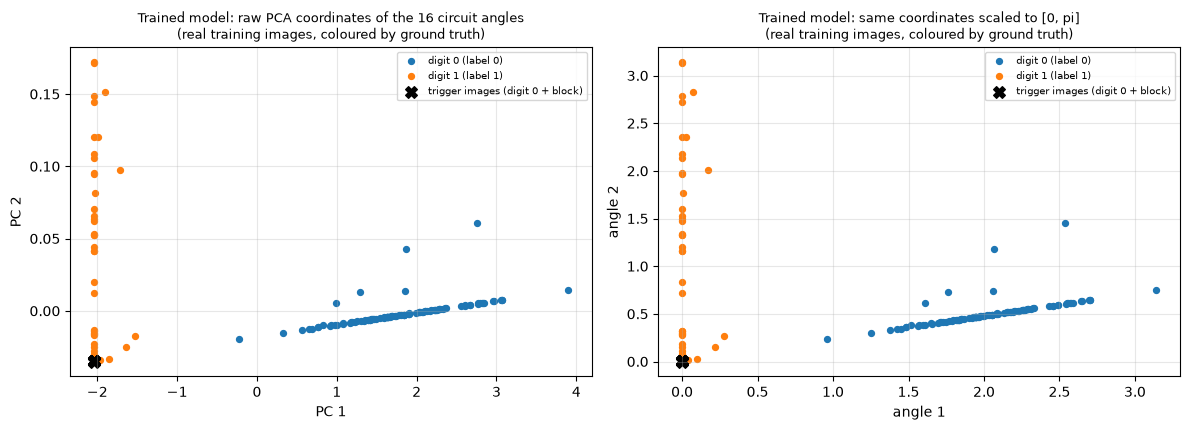

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
pairs_all = PAIRS_T1; xs_ = np.arange(len(pairs_all)); w = 0.26
for ax, metric, ttl in ((axes[0], "trig_acc", "Trigger accuracy (watermark extraction), %"), (axes[1], "clean_acc", "Clean-test accuracy (original task), %")):
    for k, (n_trig, ordering, col, lab) in enumerate(((0, "random", "C7", "no trigger (non-watermarked)"), (10, "paired", "C0", "10 triggers (grouped + paired)"), (20, "paired", "C2", "20 triggers"))):
        m_, s_ = [], []
        for pair in pairs_all:
            s = Q[(Q.pair == f"{pair[0]}/{pair[1]}") & (Q.n_trig == n_trig) & (Q.ordering == ordering)][metric] * 100
            m_.append(s.mean() if len(s) else np.nan); s_.append(s.std(ddof=0) if len(s) else 0)
        ax.bar(xs_ + (k - 1) * w, m_, w, yerr=s_, capsize=2, color=col, label=lab, alpha=0.85)
        pm = []
        for pair in pairs_all:
            if n_trig == 20: pm.append(PAPER_T2.get(pair, (np.nan, np.nan))[0 if metric == "clean_acc" else 1])
            else: pm.append(PAPER_T1[pair][0 if n_trig == 0 else 1][0 if metric == "clean_acc" else 1])
        ax.scatter(xs_ + (k - 1) * w, pm, marker="D", c="k", s=22, zorder=5, label="paper" if k == 0 else None)
    ax.set_xticks(xs_); ax.set_xticklabels([f"{a}/{b}" for a, b in pairs_all]); ax.set_xlabel("digit pair"); ax.set_title(ttl, fontsize=10); ax.set_ylim(0, 105); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# training loss of the first watermarked model: the batches that contain a trigger pair are marked
key = (PAIRS_T1[0][0], PAIRS_T1[0][1], 10, "paired", "quantum", FIRST_SEED)
model_w, losses = MODELS[key]
L = pd.DataFrame(losses, columns=["epoch", "batch", "loss", "has_trigger"]); L["step"] = np.arange(len(L))
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(L.step, L.loss, lw=0.8, label="batch loss (batch of 4)"); ax.plot(L.step, L.loss.rolling(10, min_periods=1).mean(), lw=2, label="moving average (10 batches)")
ax.scatter(L.step[L.has_trigger], L.loss[L.has_trigger], c="k", marker="X", s=40, zorder=5, label="batch with a trigger pair")
for e in range(1, EPOCHS): ax.axvline(e * (200 // BATCH), c="gray", ls=":")
ax.set_xlabel("training step (4 epochs of 50 batches)"); ax.set_ylabel("binary cross-entropy"); ax.set_title(f"Watermarked QNN, digits {key[0]}/{key[1]}, 10 triggers, seed {key[5]}", fontsize=10); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# confusion matrices of the same model: clean test set (attack = none; label 1 as positive) and trigger set
clean_imgs, clean_y, trig_imgs = build_test_sets(key[0], key[1], key[5])
pc, pt = predict_label(model_w, clean_imgs), predict_label(model_w, trig_imgs)
cm = confusion_matrix(clean_y, pc, labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, M, labels_x, labels_y, ttl in ((axes[0], cm, [f"pred {key[0]}", f"pred {key[1]}"], [f"true {key[0]}", f"true {key[1]}"], "clean test set (100 + 100)"),
                                       (axes[1], np.array([[(pt == 0).sum(), (pt == 1).sum()]]), [f"pred {key[0]} (label 0)", "pred label 1 (trigger label)"], [f"trigger set (100)"], "trigger test set")):
    ax.imshow(M, cmap="Blues"); ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(labels_x, fontsize=8); ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(labels_y, fontsize=8); ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]): ax.text(j, i, int(M[i, j]), ha="center", va="center", color="k", fontsize=12)
    ax.set_title(ttl, fontsize=10)
plt.tight_layout(); plt.show()

# the 16 angles that enter the circuit (outputs of Linear + ReLU) for the training sequence of that model: PCA fitted on the training split
imgs_k, y_k, trig_k = build_training_sequence(key[0], key[1], 10, key[5])
with torch.no_grad(): A_tr = model_w.angles(torch.tensor(to_input(imgs_k))).numpy()
pca_a = PCA(n_components=2, random_state=SEED).fit(A_tr[~trig_k]); Z = pca_a.transform(A_tr)
lo, hi = Z[~trig_k].min(0), Z[~trig_k].max(0); Zs = np.clip((Z - lo) / (hi - lo) * np.pi, 0, np.pi)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, ZZ, ttl, lab in ((axes[0], Z, "raw PCA coordinates of the 16 circuit angles", "PC"), (axes[1], Zs, "same coordinates scaled to [0, pi]", "angle")):
    for lbl, col, name in ((0, "C0", f"digit {key[0]} (label 0)"), (1, "C1", f"digit {key[1]} (label 1)")):
        mk = (~trig_k) & (y_k == lbl); ax.scatter(ZZ[mk, 0], ZZ[mk, 1], s=18, c=col, label=name)
    ax.scatter(ZZ[trig_k, 0], ZZ[trig_k, 1], s=70, c="k", marker="X", label=f"trigger images (digit {key[0]} + block)")
    ax.set_xlabel(lab + " 1"); ax.set_ylabel(lab + " 2"); ax.set_title(f"Trained model: {ttl}\n(real training images, coloured by ground truth)", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 8. Ownership verification (paper Eq. 5 to 7)

When a dispute arises the owner sends the trigger set R to the suspect model and counts how many answers equal the trigger label. The suspect is declared a copy if its accuracy on R exceeds that of a reference non-watermarked model by more than a large threshold Delta (here 0.5, a CHOICE). The cell first asserts once more that the *trained* circuit equals Qiskit's, then runs the test for every watermarked model against independently trained non-watermarked models of other seeds, and also counts false alarms (a non-watermarked model wrongly declared a copy).

In [13]:
# ---- the trained circuit is still the Qiskit circuit: assert the simulator against Statevector with the TRAINED weights and the TRAINED first layer ----
imgs_chk = np.concatenate([XTE[:4], add_trigger(XTE[:2])])
with torch.no_grad(): ang_chk = model_w.angles(torch.tensor(to_input(imgs_chk)))
ref = np.array([qiskit_expectation(r, model_w.weight.detach().numpy()) for r in ang_chk.numpy()])
mine = circuit_expectation(ang_chk, model_w.weight.detach().view(REPS, N_QUBITS))[:, 0].numpy()
assert np.abs(ref - mine).max() < 1e-5
print("trained model: simulator vs Qiskit Statevector on 4 clean + 2 trigger images: max |difference| = %.1e (assert passed)" % np.abs(ref - mine).max())
print("circuit output <Z^16> clean:", np.round(mine[:4], 4), "| trigger:", np.round(mine[4:], 4))
with torch.no_grad(): p_chk = model_w(torch.tensor(to_input(imgs_chk))).numpy()
print("model probabilities of label 1 (clean 0-digit images, then trigger images):", np.round(p_chk, 3))

# ---- ownership verification, Eq. (7): black-box queries with the trigger set R only ----
# decision rule: the suspect model is declared the owner's if  acc_R(suspect) - acc_R(reference non-watermarked model) > DELTA
rows, fa = [], []
for pair in PAIRS_T1:
    pn = f"{pair[0]}/{pair[1]}"
    wm = Q[(Q.pair == pn) & (Q.n_trig == 10) & (Q.ordering == "paired")].set_index("seed").trig_acc
    cl = Q[(Q.pair == pn) & (Q.n_trig == 0)].set_index("seed").trig_acc
    for s in SEEDS:
        others = [t for t in SEEDS if t != s]
        ref_acc = cl.loc[others].mean() if others else cl.loc[s]            # reference: independently trained non-watermarked model(s), other seeds when available
        rows.append(dict(pair=pn, seed=s, acc_R_suspect=wm.loc[s], acc_R_reference=ref_acc, gap=wm.loc[s] - ref_acc, verified=bool(wm.loc[s] - ref_acc > DELTA)))
        for s2 in others:                                                    # false alarm: an innocent non-watermarked model (seed s2) tested against a reference (seed s)
            fa.append(bool(cl.loc[s2] - cl.loc[s] > DELTA))
OWN = pd.DataFrame(rows)
print(f"\nownership test (Delta = {DELTA}): watermarked models verified in {int(OWN.verified.sum())} / {len(OWN)} cases (pair x seed); mean accuracy gap {OWN.gap.mean() * 100:.1f} points")
print(f"false-alarm test: an innocent non-watermarked model is wrongly 'verified' in {int(np.sum(fa))} / {len(fa)} comparisons" if fa else "false-alarm test needs at least two seeds")
display(OWN.round(3))

trained model: simulator vs Qiskit Statevector on 4 clean + 2 trigger images: max |difference| = 2.1e-07 (assert passed)
circuit output <Z^16> clean: [-0.6996 -0.264   1.     -0.0311] | trigger: [1. 1.]
model probabilities of label 1 (clean 0-digit images, then trigger images): [0.156 0.296 0.819 0.394 0.819 0.819]

ownership test (Delta = 0.5): watermarked models verified in 12 / 25 cases (pair x seed); mean accuracy gap 42.6 points
false-alarm test: an innocent non-watermarked model is wrongly 'verified' in 9 / 100 comparisons


,pair,seed,acc_R_suspect,acc_R_reference,gap,verified
0,0/1,42,1.00,0.145,0.855,True
1,0/1,43,0.00,0.178,-0.178,False
2,0/1,44,0.02,0.167,-0.148,False
3,0/1,45,0.21,0.088,0.122,False
4,0/1,46,0.29,0.132,0.157,False
5,2/3,42,1.00,0.348,0.652,True
6,2/3,43,0.64,0.387,0.253,False
7,2/3,44,0.44,0.385,0.055,False
8,2/3,45,0.46,0.138,0.322,False
9,2/3,46,1.00,0.292,0.708,True


## 9. Side by side with the paper: one verdict per claim

Rule (as in the other notebooks): a number is **reproduced** if it lies within 2 accuracy points of the paper's value, otherwise **exceeded** or **not reached** (with the gap); a qualitative claim is checked with the rule printed next to it; **cannot be checked** when the paper gives no number. The row-by-row table values are seed means of only 2 to 3 runs of 200 training images each, so differences of several points between runs are expected.

In [14]:
V = []          # (claim, paper, this notebook, verdict, rule)
def within(a, b, tol): return "reproduced" if abs(a - b) <= tol else ("exceeded" if a > b else "not reached")
TOL = 2.0       # accuracy points (brief: "reproduced" = within 2 accuracy points)

# ---- Table 1, row by row (seed means) ----
for pair in PAIRS_T1:
    for n_trig in (0, 10):
        ca, _, ta, _, n = agg(pair, n_trig, "random" if n_trig == 0 else "paired"); pc, pt = PAPER_T1[pair][0 if n_trig == 0 else 1]
        tag = f"Table 1, digits {pair[0]}/{pair[1]}, {n_trig} triggers"
        V.append((tag + ": clean accuracy", f"{pc} %", f"{ca:.1f} %", within(ca, pc, TOL), f"within {TOL:g} points ({n} seeds)"))
        V.append((tag + ": trigger accuracy", f"{pt} %", f"{ta:.1f} %", within(ta, pt, TOL), f"within {TOL:g} points"))
# ---- Table 2 ----
for pair in PAIRS_T2:
    ca, _, ta, _, n = agg(pair, 20, "paired"); pc, pt = PAPER_T2[pair]; tag = f"Table 2, digits {pair[0]}/{pair[1]}, 20 triggers"
    V.append((tag + ": clean accuracy", f"{pc} %", f"{ca:.1f} %", within(ca, pc, TOL), f"within {TOL:g} points"))
    V.append((tag + ": trigger accuracy", f"{pt} %", f"{ta:.1f} %", within(ta, pt, TOL), f"within {TOL:g} points"))

# ---- the paper's qualitative claims ----
gaps = {p: agg(p, 10, "paired")[2] - agg(p, 0, "random")[2] for p in PAIRS_T1}
V.append(("Claim: the watermarked QNN reacts to the trigger set far more than the non-watermarked one (accuracy gap on the trigger set, all pairs)", "gap 40-74 points over the five pairs (Table 1)", ", ".join(f"{p[0]}/{p[1]}: {g:+.0f}" for p, g in gaps.items()),
          "reproduced" if min(gaps.values()) >= 40 else "not reached", "every pair has a gap >= 40 points (the paper's smallest gap)"))
tw = {p: agg(p, 10, "paired")[2] for p in PAIRS_T1}
V.append(("Claim: with 10 triggers the watermark is extracted with 79-98 % accuracy", "79-98 %", ", ".join(f"{p[0]}/{p[1]}: {v:.0f} %" for p, v in tw.items()), "reproduced" if min(tw.values()) >= 79 else "not reached", "trigger accuracy >= 79 % for every pair"))
tn = {p: agg(p, 0, "random")[2] for p in PAIRS_T1}
V.append(("Claim: the non-watermarked model classifies 23-40 % of the trigger set with the trigger label", "23-40 %", ", ".join(f"{p[0]}/{p[1]}: {v:.0f} %" for p, v in tn.items()), "reproduced" if all(21 <= v <= 42 for v in tn.values()) else ("not reached" if max(tn.values()) < 21 else "exceeded"), "all pairs within 23-40 % (+-2 points)"))
drops = {p: agg(p, 0, "random")[0] - agg(p, 10, "paired")[0] for p in PAIRS_T1}
V.append(("Claim: watermarking costs only a small amount of clean accuracy (0.5-3 points); drop = non-watermarked minus watermarked, negative = the watermarked model is better", "drop 0.5-3 points", ", ".join(f"{p[0]}/{p[1]}: {d:+.1f}" for p, d in drops.items()), "reproduced" if max(drops.values()) <= 3 + TOL else "not reached", "largest clean-accuracy drop <= 3 + 2 points"))
if PAIRS_T2:
    t20 = {p: agg(p, 20, "paired")[2] for p in PAIRS_T2}; t10 = {p: agg(p, 10, "paired")[2] for p in PAIRS_T2 if p in PAIRS_T1}
    V.append(("Claim: with 20 triggers the trigger samples are classified perfectly (at a small cost in clean accuracy)", "100 % for 3 pairs (Table 2)", ", ".join(f"{p[0]}/{p[1]}: {v:.0f} % (10 triggers: {t10.get(p, float('nan')):.0f} %)" for p, v in t20.items()),
              "reproduced" if min(t20.values()) >= 98 else "not reached", "trigger accuracy >= 98 % for every Table-2 pair"))
    V.append(("Claim: a larger trigger set raises the trigger accuracy", "+3 to +21 points (Table 2 vs Table 1)", ", ".join(f"{p[0]}/{p[1]}: {t20[p] - t10[p]:+.0f}" for p in t10), "reproduced" if all(t20[p] > t10[p] for p in t10) else "not reached", "20-trigger accuracy above the 10-trigger accuracy for every pair"))
# sample-order ablation
if len(PAIRS_RANDOM):
    pm = [Q[(Q.pair == f"{p[0]}/{p[1]}") & (Q.n_trig == 10) & (Q.ordering == "paired")].trig_acc for p in PAIRS_RANDOM]
    rm = [Q[(Q.pair == f"{p[0]}/{p[1]}") & (Q.n_trig == 10) & (Q.ordering == "random")].trig_acc for p in PAIRS_RANDOM]
    pa, ra = np.concatenate(pm), np.concatenate(rm)
    V.append(("Claim: grouped + paired order gives better and more stable watermark extraction than random order", "'better watermarking performance and better stability' (not tabulated)", f"trigger acc paired {100 * pa.mean():.1f} +- {100 * pa.std():.1f} % (min {100 * pa.min():.0f}) vs random {100 * ra.mean():.1f} +- {100 * ra.std():.1f} % (min {100 * ra.min():.0f}); {len(pa)} runs each",
              "reproduced" if (pa.mean() > ra.mean() and pa.std() <= ra.std()) else "not reached", "higher mean AND not larger spread than random order"))
V.append(("Claim: ownership can be verified from the black-box predictions on a small trigger set (Eq. 7)", "'reliably embed and extract'", f"verified in {int(OWN.verified.sum())} / {len(OWN)} cases with Delta = {DELTA}" + (f"; false alarms {int(np.sum(fa))} / {len(fa)}" if fa else ""),
          "reproduced" if OWN.verified.all() else "not reached", "every watermarked model passes the test"))
V.append(("Quantum layer vs a classical stand-in", "not reported", "see the table above (informational)", "cannot be checked", "the paper has no classical comparison"))
VD = pd.DataFrame(V, columns=["claim", "paper", "this notebook", "verdict", "rule"])
pd.set_option("display.max_colwidth", 140, "display.width", 250)
display(VD[["claim", "paper", "this notebook", "verdict"]])
print(VD.verdict.value_counts().to_string())

,claim,paper,this notebook,verdict
0,"Table 1, digits 0/1, 0 triggers: clean accuracy",86 %,93.1 %,exceeded
1,"Table 1, digits 0/1, 0 triggers: trigger accuracy",23 %,14.2 %,not reached
2,"Table 1, digits 0/1, 10 triggers: clean accuracy",83.5 %,92.5 %,exceeded
3,"Table 1, digits 0/1, 10 triggers: trigger accuracy",97 %,30.4 %,not reached
4,"Table 1, digits 2/3, 0 triggers: clean accuracy",81.5 %,77.2 %,not reached
5,"Table 1, digits 2/3, 0 triggers: trigger accuracy",37 %,31.0 %,not reached
6,"Table 1, digits 2/3, 10 triggers: clean accuracy",79 %,81.2 %,exceeded
7,"Table 1, digits 2/3, 10 triggers: trigger accuracy",98 %,70.8 %,not reached
8,"Table 1, digits 4/5, 0 triggers: clean accuracy",85 %,91.4 %,exceeded
9,"Table 1, digits 4/5, 0 triggers: trigger accuracy",37 %,8.2 %,not reached


verdict
not reached          21
exceeded              9
reproduced            4
cannot be checked     1


## Reading the paper critically

**What this re-run supports (full run: 5 digit pairs, 5 seeds, 25 watermarked models with 10 triggers and 15 with random order).**
- The *direction* of the paper's claim holds. With 10 triggers the watermarked QNNs answer the trigger set with the trigger label more often than non-watermarked QNNs for all five digit pairs (mean gap +40 to +67 points for 2/3, 4/5 and 8/9, +27 for 6/7, only +16 for 0/1), and 20 triggers give a higher trigger accuracy than 10 triggers for all three Table-2 pairs (+3 to +22 points). Clean accuracy of watermarked and non-watermarked models is comparable (no pair loses more than about 5 points on average).
- Many individual runs succeed completely (trigger accuracy 99 to 100 %), which shows the mechanism works: a 7 x 7 white block can be turned into a backdoor of this 16-qubit hybrid network from 10 samples.

**What it does not support.**
- *Reliability.* The paper reports 79 to 98 % (10 triggers) and 100 % (20 triggers) in a single run per cell. Here the same protocol gives a **bimodal** outcome: in some seeds the watermark is embedded perfectly, in others it fails completely (trigger accuracy 0 to 2 %), so the means are 30 to 82 % with a standard deviation of 25 to 43 points, and 20 triggers give 51 to 94 %. With the ownership rule of Eq. (7) and Delta = 0.5 only 12 of 25 watermarked models are verified. The paper's single numbers could therefore be lucky seeds, or the unspecified details we had to choose (pixel scaling, circuit observable, weight initialisation, trigger position, ordering across epochs) matter a lot; the paper cannot tell us.
- *The claimed benefit of the grouped and paired order.* The paper says the order is "better and more stable" than random order. Over 15 paired and 15 random-order runs the trigger accuracy is the same within noise (about 61 +- 40 % versus 55 +- 40 %); both fail in a similar number of runs. This claim is not tabulated in the paper and is not reproduced here.
- *Differences of 1 to 3 points are noise.* The paper discusses clean-accuracy drops of 0.5 to 3 points. The standard deviation over seeds is 3 to 18 points, and non-watermarked models sometimes collapse to a constant prediction (50 % clean accuracy, and then a trigger accuracy of 0 or 100 %, which also produces false alarms in the ownership test: 9 of 100 comparisons of two non-watermarked models).
- *Trigger accuracy of the non-watermarked model* is 8 to 31 % here (paper: 23 to 40 %), so the "baseline" is not a fixed number but depends on the model and its random state.

**Design weaknesses worth remembering.**
- *Little of the model is quantum.* A Linear(784, 16) layer does the feature extraction; the circuit then reduces the 16 numbers to a single parity expectation value, and only 16 of the 32 circuit weights can influence the output (the last RZ layer comes before a Z-basis measurement). Compare the classical stand-in in section 6 (same first layer, a one-neuron classical layer instead of the circuit): it reaches 93 to 99.7 % clean accuracy and, with 10 triggers, 85 to 99.6 % trigger accuracy, and RandomForest and SVC embed the same backdoor at 100 %. The watermark is a generic property of backdoors in learners with enough capacity; the narrow quantum bottleneck mainly makes it less reliable.
- *No robustness evaluation.* IP protection means surviving fine-tuning, pruning, overwriting with other triggers and model extraction (the topic of this folder), and being unforgeable. None of these is tested; exercise 4 starts that. The trigger is also visible and simple, so an attacker who knows the scheme can look for it.
- *No false-positive analysis, no statistics.* Delta is "a large threshold" without a value; single runs per cell; 200 training images; binary MNIST only. The claim of "exponential speedups" in the introduction is not supported by anything done.
- *The simulation is exact.* No shot noise, no device noise: on real hardware the single-number readout of a 16-qubit parity would be much noisier.

**Choices that may explain differences.** Pixel scaling (raw 0 to 255 collapsed to chance in a preliminary run), the top-left trigger position, the observable (Z on all qubits, EstimatorQNN default), uniform [-1, 1] weight initialisation, fixed sequence order in every epoch, and batches of 4 that always keep a trigger pair together at the end of each group. Changing any of them is a one-line edit in the configuration or engine cells.

**Runtime of the committed execution.** The committed outputs come from one complete `FAST_MODE = False` run (5 digit pairs, 5 seeds, 130 trained models) with a single CPU thread on a heavily shared machine: 94 minutes in total (an identical earlier run, with identical numbers, took 58 minutes; the comment in the configuration cell quotes that earlier figure). On an idle CPU expect roughly 30 to 60 minutes; `FAST_MODE = True` (2 digit pairs, 3 seeds) takes 15 to 20 minutes on the same machine.

## Exercises

1. **Seeds.** Increase `N_SEEDS` to 10 for one digit pair and plot the distribution of trigger accuracy for 10 triggers versus 20 triggers. How often does the watermark fail completely?
2. **Trigger position and size.** Change `TRIGGER_POS` to the bottom-right corner and `TRIGGER_SIZE` to 4. Does the non-watermarked model still react to the block (trigger accuracy without watermark)? What does that do to the accuracy gap that the ownership test relies on?
3. **Order matters?** Add a third ordering that puts all trigger pairs at the very end of the sequence. Compare it with the grouped/paired order and the random order on digit pair 4/5.
4. **Removal attacks.** Fine-tune a watermarked model for one epoch on clean data only (no trigger samples), or set the smallest 20 percent of the weights of the first layer to zero (pruning). Does the trigger accuracy survive? (The paper does not test robustness at all.)
5. **Observable.** Replace the parity observable by the average of the single-qubit Z expectations in `circuit_expectation` (and in the Qiskit check). Does the clean accuracy of the non-watermarked model go up, and does the watermark still embed?